# 03. Modelling and validation

## Objective

At contact capacities of 10% and 20%, do Logistic Regression and Random
Forest identify a larger share of customers with recorded churn than
random selection and a simple rule-based approach? All four methods
are compared at the same contact capacities using recall and lift.

## Inputs

- Development dataset (80% split): `churn-bigml-80.csv`
- Data audit decisions: `audit_decisions.json`
- Exploratory analysis decisions: `eda_decisions.json`

## Validation approach

Nested stratified cross-validation is applied to the development data.
Within each outer training split, inner cross-validation is used to
select feature sets, model hyperparameters and rule thresholds. The
corresponding outer validation fold is used to estimate performance.
Preprocessing steps that learn from data, such as scaling and encoding,
are fitted only on the training partition of each split.

Because the timing of `Customer service calls` relative to churn is
undocumented, the sensitivity analysis repeats the model and rule
comparisons without this variable. Both versions use the same validation
splits and tuning criterion. Model settings and applicable rule
thresholds are selected separately for each version.

## Scope

This notebook uses the development data only. The reserved 20% test split
will be used in `04_final_evaluation.ipynb` after the model and rule
settings have been fixed.

## 1. Setup and data loading

In [1]:
from pathlib import Path
import json
import os

import pandas as pd

# Locate the project in Colab or in a local Jupyter session.
if "COLAB_RELEASE_TAG" in os.environ:
    from google.colab import drive

    drive.mount("/content/drive")
    PROJECT = Path("/content/drive/MyDrive/bda-churn-capstone")
else:
    working_dir = Path.cwd()
    PROJECT = working_dir.parent if working_dir.name == "notebooks" else working_dir

audit_path = PROJECT / "data" / "processed" / "audit_decisions.json"
eda_path = PROJECT / "data" / "processed" / "eda_decisions.json"

for path in (audit_path, eda_path):
    if not path.is_file():
        raise FileNotFoundError(f"Required file not found: {path}")

with audit_path.open(encoding="utf-8") as file:
    audit_decisions = json.load(file)

with eda_path.open(encoding="utf-8") as file:
    eda_decisions = json.load(file)

# Load the development dataset.
data_path = PROJECT / "data" / "raw" / audit_decisions["development_file"]
if not data_path.is_file():
    raise FileNotFoundError(f"Required file not found: {data_path}")

dev = pd.read_csv(data_path)

target = audit_decisions["target"]
initial_features = eda_decisions["initial_features"]
categorical_cols = initial_features["categorical"]
numeric_cols = initial_features["numeric"]
excluded_cols = initial_features["excluded"]
feature_cols = categorical_cols + numeric_cols

expected_cols = feature_cols + excluded_cols + [target]
if len(expected_cols) != len(set(expected_cols)):
    raise ValueError("The feature lists overlap or include the target.")

missing_cols = set(expected_cols) - set(dev.columns)
unexpected_cols = set(dev.columns) - set(expected_cols)

if missing_cols or unexpected_cols:
    raise ValueError(
        "Development columns differ from the EDA configuration. "
        f"Missing: {sorted(missing_cols)}. "
        f"Unexpected: {sorted(unexpected_cols)}."
    )

if len(dev) != 2666:
    raise ValueError(f"Expected 2,666 development records, found {len(dev):,}.")

# Encode the binary target as 0 (no churn) and 1 (churn).
target_labels = dev[target].astype("string").str.strip().str.lower()
encoded_target = target_labels.map({"false": 0, "true": 1, "0": 0, "1": 1})

if encoded_target.isna().any() or encoded_target.nunique() != 2:
    raise ValueError("Expected a complete binary Churn target with both classes.")

X = dev[feature_cols].copy()
y = encoded_target.astype(int).rename(target)

# Read the evaluation settings recorded in the EDA notebook.
RANDOM_SEED = eda_decisions["random_seed"]
evaluation = eda_decisions["evaluation"]
CONTACT_CAPACITIES = tuple(evaluation["contact_capacities"])

if evaluation["capacity_rounding"] != "floor":
    raise ValueError("Expected floor rounding for contact capacities.")

# Create the notebook output directories.
FIGURES = PROJECT / "reports" / "figures"
TABLES = PROJECT / "reports" / "tables"

FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

print(f"Project path: {PROJECT}")
print(f"Development records: {len(dev):,}")
print(f"Churn records: {y.sum():,} ({y.mean():.1%})")
print(f"Initial predictors: {X.shape[1]}")
print(f"Excluded predictors: {', '.join(excluded_cols)}")
print(f"Contact capacities: {', '.join(f'{c:.0%}' for c in CONTACT_CAPACITIES)}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project path: /content/drive/MyDrive/bda-churn-capstone
Development records: 2,666
Churn records: 388 (14.6%)
Initial predictors: 15
Excluded predictors: Total day charge, Total eve charge, Total night charge, Total intl charge
Contact capacities: 10%, 20%


## 2. Evaluation metrics

All four methods are evaluated using the same metrics at contact
capacities of 10% and 20%. For a validation fold with $n$ customers
and a contact capacity $c$, the number of customers selected is
$k = \lfloor c \times n \rfloor$.

Customers are ranked from highest to lowest score, using the
tie-breaking procedure defined for each method. The first $k$
customers form the contact list.

- **Recall at capacity** is the proportion of all customers with
  recorded churn in the validation fold who appear in the contact list.
- **Lift at capacity** is the churn rate in the contact list divided
  by the churn rate across the full validation fold. A lift of 1 means
  the contact list has the same churn rate as the full validation fold,
  which is the value expected under random selection.

For tuning, each candidate feature set and model configuration or
rule-threshold setting is scored in each inner validation fold using
the equally weighted mean of `Recall@10%` and `Recall@20%`. For each
model and the rule-based approach, the candidate with the highest mean
score across the inner validation folds is selected. Recall and lift
are reported separately for each capacity on the outer validation folds.

In [2]:
# === 2. Evaluation metrics ===
from math import floor

import numpy as np


def evaluate_at_capacities(y_true, ranked_positions, capacities=CONTACT_CAPACITIES):
    """Evaluate a ranked customer list at each contact capacity."""
    labels = np.asarray(y_true)
    ranking = np.asarray(ranked_positions)

    if labels.ndim != 1 or not np.isin(labels, [0, 1]).all():
        raise ValueError("y_true must be a one-dimensional array of binary labels.")

    n_customers = len(labels)
    if (
        ranking.shape != (n_customers,)
        or not np.issubdtype(ranking.dtype, np.integer)
        or not np.array_equal(np.sort(ranking), np.arange(n_customers))
    ):
        raise ValueError("Ranking must contain every fold position exactly once.")

    total_churners = int(labels.sum())
    if total_churners == 0:
        raise ValueError("Recall and lift require at least one churner in the fold.")

    fold_churn_rate = total_churners / n_customers
    results = []

    for capacity in capacities:
        n_selected = floor(capacity * n_customers)
        if not 1 <= n_selected <= n_customers:
            raise ValueError(f"Invalid contact count at capacity {capacity:.0%}.")

        selected_positions = ranking[:n_selected]
        churners_selected = int(labels[selected_positions].sum())
        contact_churn_rate = churners_selected / n_selected

        results.append({
            "capacity": capacity,
            "n_selected": n_selected,
            "churners_selected": churners_selected,
            "recall": churners_selected / total_churners,
            "lift": contact_churn_rate / fold_churn_rate,
        })

    return pd.DataFrame(results)


def tuning_score(y_true, ranked_positions):
    """Return the equally weighted mean recall across the two capacities."""
    results = evaluate_at_capacities(y_true, ranked_positions)
    return float(results["recall"].mean())


# Sanity check: a perfect ranking should reach the recall ceiling.
perfect_ranking = np.argsort(-y.to_numpy(), kind="stable")
display(evaluate_at_capacities(y, perfect_ranking).round(3))
print(f"Tuning score (perfect ranking): {tuning_score(y, perfect_ranking):.3f}")

,capacity,n_selected,churners_selected,recall,lift
0,0.1,266,266,0.686,6.871
1,0.2,533,388,1.000,5.002


Tuning score (perfect ranking): 0.843


### Ranking and tie-breaking

Customers are ranked from highest to lowest predicted churn probability
for Logistic Regression and Random Forest. For the rule-based approach,
customers are ranked first by rule score and then by `Total day minutes`,
both in descending order.

Any remaining ties are resolved using random values generated with a
fixed seed (42). This gives reproducible rankings when the input rows
are in the same order.

In [3]:
# === Ranking with reproducible tie-breaking ===
import numpy as np


def rank_positions(sort_keys, seed=RANDOM_SEED):
    """Rank fold positions using descending keys in priority order.

    Remaining ties are broken randomly using a fixed seed.
    """
    keys = [np.asarray(key, dtype=float) for key in sort_keys]

    if not keys or keys[0].ndim != 1:
        raise ValueError("Provide at least one one-dimensional sort key.")

    n_customers = len(keys[0])

    if any(key.shape != (n_customers,) for key in keys):
        raise ValueError("All sort keys must be one-dimensional and of equal length.")

    if any(not np.isfinite(key).all() for key in keys):
        raise ValueError("Sort keys must contain only finite values.")

    random_key = np.random.default_rng(seed).random(n_customers)

    # lexsort gives the last key highest priority. Negation sorts descending.
    descending_keys = [-key for key in reversed(keys)]
    return np.lexsort([random_key, *descending_keys])


# Check key priority and reproducible tie-breaking.
example_scores = np.array([0.9, 0.5, 0.5, 0.5, 0.1])
example_minutes = np.array([100, 200, 300, 300, 500])

example_ranking = rank_positions([example_scores, example_minutes])

assert example_ranking[0] == 0
assert set(example_ranking[1:3]) == {2, 3}
assert example_ranking[3:].tolist() == [1, 4]
assert np.array_equal(
    example_ranking,
    rank_positions([example_scores, example_minutes]),
)

print("Ranking checks passed.")

Ranking checks passed.


## 3. Cross-validation design

The development data are split into five stratified outer folds,
with shuffling and a fixed random seed of 42. Each outer validation
fold contains 533 or 534 customers, including 77 or 78 customers with
recorded churn. The 10% contact capacity allows 53 contacts in each
outer validation fold.

Five outer folds were chosen to retain more churn cases and contact
slots per validation fold than a ten-fold design. This makes recall
at 10% capacity less sensitive to a change of one customer in the
number of churn cases captured.

Within each outer training partition, five stratified inner folds
are used to select feature sets, model hyperparameters and rule
thresholds. Each inner validation fold contains 426 or 427 customers,
including 62 or 63 customers with recorded churn. The corresponding
outer validation fold is used to estimate performance.

Stratification keeps the churn rate close to the development-set rate
of 14.6%. The outer validation fold assignment is saved, and the same
outer and inner splits are reused for the main analysis and the
sensitivity analysis without `Customer service calls`.

In [4]:
# === 3. Cross-validation design ===
from math import floor

import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold

N_OUTER_FOLDS = 5
N_INNER_FOLDS = 5

outer_cv = StratifiedKFold(
    n_splits=N_OUTER_FOLDS,
    shuffle=True,
    random_state=RANDOM_SEED,
)
outer_splits = list(outer_cv.split(X, y))

inner_cv = StratifiedKFold(
    n_splits=N_INNER_FOLDS,
    shuffle=True,
    random_state=RANDOM_SEED,
)

# Inner positions are relative to the corresponding outer training partition.
inner_splits_by_outer_fold = {}
for fold, (train_positions, _) in enumerate(outer_splits, start=1):
    X_train = X.iloc[train_positions]
    y_train = y.iloc[train_positions]
    inner_splits_by_outer_fold[fold] = list(inner_cv.split(X_train, y_train))

# Record outer validation membership and summarise the splits.
outer_fold = np.full(len(y), -1, dtype=int)
summary_rows = []

for fold, (train_positions, valid_positions) in enumerate(outer_splits, start=1):
    outer_fold[valid_positions] = fold

    y_train = y.iloc[train_positions]
    y_valid = y.iloc[valid_positions]

    inner_sizes = []
    inner_churners = []

    for _, inner_valid_positions in inner_splits_by_outer_fold[fold]:
        y_inner_valid = y_train.iloc[inner_valid_positions]
        inner_sizes.append(len(y_inner_valid))
        inner_churners.append(int(y_inner_valid.sum()))

    row = {
        "Outer fold": fold,
        "Training customers": len(y_train),
        "Validation customers": len(y_valid),
        "Validation churners": int(y_valid.sum()),
        "Validation churn rate (%)": y_valid.mean() * 100,
    }

    for capacity in CONTACT_CAPACITIES:
        row[f"Contacts at {capacity:.0%}"] = floor(capacity * len(y_valid))

    row["Inner validation sizes"] = f"{min(inner_sizes)}–{max(inner_sizes)}"
    row["Inner validation churners"] = (
        f"{min(inner_churners)}–{max(inner_churners)}"
    )
    summary_rows.append(row)

if (outer_fold == -1).any():
    raise ValueError("Some records were not assigned to an outer fold.")

fold_summary = pd.DataFrame(summary_rows).set_index("Outer fold")
display(fold_summary.round({"Validation churn rate (%)": 1}))

# Save the outer fold assignment and summary table.
fold_assignment = pd.DataFrame({
    "row_position": np.arange(len(y)),
    "outer_fold": outer_fold,
})

fold_assignment_path = PROJECT / "data" / "processed" / "outer_folds.csv"
fold_summary_path = TABLES / "modelling_fold_summary.csv"

fold_assignment.to_csv(fold_assignment_path, index=False)
fold_summary.to_csv(fold_summary_path, encoding="utf-8")

print(f"Saved {fold_assignment_path.relative_to(PROJECT)}")
print(f"Saved {fold_summary_path.relative_to(PROJECT)}")

,Training customers,Validation customers,Validation churners,Validation churn rate (%),Contacts at 10%,Contacts at 20%,Inner validation sizes,Inner validation churners
Outer fold,,,,,,,,
1,2132,534,78,14.6,53,106,426–427,62–62
2,2133,533,77,14.4,53,106,426–427,62–63
3,2133,533,77,14.4,53,106,426–427,62–63
4,2133,533,78,14.6,53,106,426–427,62–62
5,2133,533,78,14.6,53,106,426–427,62–62


Saved data/processed/outer_folds.csv
Saved reports/tables/modelling_fold_summary.csv


## 4. Baselines

Random selection and a simple rule-based approach provide reference
points for the models. Both are evaluated on the same outer validation
folds and at the same contact capacities as the models.

### Random selection

Random selection represents a retention campaign that contacts
customers without prioritisation. Its expected recall equals the
actual share of customers contacted after rounding down, and its
expected lift is 1.

For each outer validation fold, 1,000 random orderings are generated
using a reproducible random number generator initialised with seed 42.
At each capacity, the mean recall and lift are reported alongside their
2.5th and 97.5th percentiles across the simulated orderings. These
percentiles describe how the outcome of a single random campaign can
vary. Random selection requires no tuning.

### Rule-based approach

The rule assigns one point for each condition met, giving each
customer a score from 0 to 3:

- `Customer service calls` ≥ $k$
- `International plan` = Yes
- `Total day minutes` ≥ $t$

Customers are ranked by rule score and then by `Total day minutes`,
both in descending order. Any remaining ties are broken using
fixed-seed random values.

Within each outer training partition, inner cross-validation compares
30 combinations of $k$ (2, 3, 4, 5 or 6) and a percentile of
`Total day minutes` (50th, 60th, 70th, 80th, 90th or 95th). For each
inner split, the candidate percentile is converted to a threshold
$t$ using only that split's training data and is then applied to
its validation data.

The combination with the highest mean inner-fold tuning score
defined in Section 2 is selected. Ties are resolved by choosing the
first candidate in ascending order of $k$, then ascending percentile.
The selected percentile is then recalculated on the full outer
training partition to obtain the threshold $t$ used to rank customers
in the corresponding outer validation fold.

In the sensitivity analysis, the `Customer service calls` condition
is removed, giving scores from 0 to 2. The percentile for $t$ is
selected again using the same inner splits and tuning criterion.
The resulting rule is evaluated on the same outer validation folds.

In [5]:
# === 4.1 Random selection baseline ===
N_RANDOM_ORDERINGS = 1000

random_rng = np.random.default_rng(RANDOM_SEED)
random_runs = []

for fold, (_, valid_positions) in enumerate(outer_splits, start=1):
    y_valid = y.iloc[valid_positions].to_numpy()

    for run in range(N_RANDOM_ORDERINGS):
        ordering = random_rng.permutation(len(y_valid))
        run_results = evaluate_at_capacities(y_valid, ordering)
        run_results["outer_fold"] = fold
        run_results["run"] = run
        random_runs.append(run_results)

random_runs = pd.concat(random_runs, ignore_index=True)

# Summarise the simulated orderings for each fold and capacity.
random_by_fold = (
    random_runs
    .groupby(["outer_fold", "capacity"])
    .agg(
        n_selected=("n_selected", "first"),
        recall_mean=("recall", "mean"),
        recall_p2_5=("recall", lambda s: s.quantile(0.025)),
        recall_p97_5=("recall", lambda s: s.quantile(0.975)),
        lift_mean=("lift", "mean"),
        lift_p2_5=("lift", lambda s: s.quantile(0.025)),
        lift_p97_5=("lift", lambda s: s.quantile(0.975)),
    )
    .reset_index()
)

# Expected recall equals the actual contact share after rounding down.
fold_sizes = {
    fold: len(valid_positions)
    for fold, (_, valid_positions) in enumerate(outer_splits, start=1)
}
random_by_fold["expected_recall"] = (
    random_by_fold["n_selected"] / random_by_fold["outer_fold"].map(fold_sizes)
)

display(random_by_fold.round(3))

# Average the fold-level means, giving each outer fold equal weight.
random_summary = (
    random_by_fold
    .groupby("capacity")[["expected_recall", "recall_mean", "lift_mean"]]
    .mean()
)

display(random_summary.round(3))

# Save the fold-level results, including the simulation percentiles.
random_by_fold_path = TABLES / "modelling_random_baseline_by_fold.csv"
random_by_fold.to_csv(random_by_fold_path, index=False)
print(f"Saved {random_by_fold_path.relative_to(PROJECT)}")

,outer_fold,capacity,n_selected,recall_mean,recall_p2_5,recall_p97_5,lift_mean,lift_p2_5,lift_p97_5,expected_recall
0,1,0.1,53,0.098,0.038,0.154,0.986,0.388,1.550,0.099
1,1,0.2,106,0.197,0.115,0.282,0.994,0.581,1.421,0.199
2,2,0.1,53,0.102,0.039,0.169,1.022,0.392,1.698,0.099
3,2,0.2,106,0.200,0.117,0.286,1.004,0.588,1.437,0.199
4,3,0.1,53,0.099,0.052,0.169,0.996,0.519,1.698,0.099
5,3,0.2,106,0.199,0.117,0.286,1.003,0.588,1.437,0.199
6,4,0.1,53,0.101,0.038,0.167,1.012,0.387,1.676,0.099
7,4,0.2,106,0.200,0.115,0.282,1.005,0.580,1.418,0.199
8,5,0.1,53,0.098,0.038,0.167,0.989,0.387,1.676,0.099
9,5,0.2,106,0.198,0.115,0.282,0.995,0.580,1.418,0.199


,expected_recall,recall_mean,lift_mean
capacity,,,
0.1,0.099,0.099,1.001
0.2,0.199,0.199,1.000


Saved reports/tables/modelling_random_baseline_by_fold.csv


In [6]:
# === 4.2 Rule-based baseline ===
from itertools import product

SERVICE_CALL_THRESHOLDS = (2, 3, 4, 5, 6)
DAY_MINUTE_PERCENTILES = (50, 60, 70, 80, 90, 95)

# Check the rule features and sensitivity variable recorded in the EDA.
rule_config = eda_decisions["rule_baseline"]
rule_features = [condition["feature"] for condition in rule_config["conditions"]]
expected_rule_features = [
    "Customer service calls",
    "International plan",
    "Total day minutes",
]

if rule_features != expected_rule_features:
    raise ValueError(f"Unexpected rule conditions: {rule_features}")

if rule_config["sensitivity_drops"] != "Customer service calls":
    raise ValueError("Unexpected sensitivity variable in eda_decisions.json.")

if not np.isfinite(X["Total day minutes"].to_numpy(dtype=float)).all():
    raise ValueError("Total day minutes must contain only finite values.")


def rank_by_rule(features, day_minutes_threshold, service_calls_threshold=None):
    """Rank customers by rule score, daytime minutes and seeded tie-breaking."""
    day_minutes = features["Total day minutes"].to_numpy(dtype=float)
    international_plan = (
        features["International plan"]
        .astype("string")
        .str.strip()
        .str.casefold()
    )

    if not international_plan.isin(["yes", "no"]).all():
        raise ValueError("International plan must contain only Yes or No.")

    scores = international_plan.eq("yes").to_numpy(dtype=int)
    scores += day_minutes >= day_minutes_threshold

    if service_calls_threshold is not None:
        service_calls = features["Customer service calls"].to_numpy(dtype=float)
        if not np.isfinite(service_calls).all():
            raise ValueError("Customer service calls must contain finite values.")
        scores += service_calls >= service_calls_threshold

    return rank_positions([scores, day_minutes])


def select_rule_thresholds(X_train, y_train, inner_splits, service_thresholds):
    """Select rule settings by mean recall across inner folds and capacities."""
    best_score = -np.inf
    best_settings = None
    training_day_minutes = X_train["Total day minutes"].to_numpy(dtype=float)

    for service_threshold, percentile in product(
        service_thresholds, DAY_MINUTE_PERCENTILES
    ):
        fold_scores = []

        for inner_train, inner_valid in inner_splits:
            day_threshold = np.percentile(
                training_day_minutes[inner_train], percentile
            )
            ranking = rank_by_rule(
                X_train.iloc[inner_valid], day_threshold, service_threshold
            )
            fold_scores.append(tuning_score(y_train.iloc[inner_valid], ranking))

        mean_score = float(np.mean(fold_scores))

        # Keep the first candidate when scores tie within numerical tolerance.
        if mean_score > best_score + 1e-12:
            best_score = mean_score
            best_settings = (service_threshold, percentile)

    service_threshold, percentile = best_settings
    return service_threshold, percentile, best_score


rule_fold_results = []

for fold, (train_positions, valid_positions) in enumerate(outer_splits, start=1):
    X_train = X.iloc[train_positions]
    y_train = y.iloc[train_positions]
    X_valid = X.iloc[valid_positions]
    y_valid = y.iloc[valid_positions]
    inner_splits = inner_splits_by_outer_fold[fold]

    for rule_version, service_thresholds in (
        ("main", SERVICE_CALL_THRESHOLDS),
        ("without_service_calls", (None,)),
    ):
        service_threshold, percentile, inner_score = select_rule_thresholds(
            X_train, y_train, inner_splits, service_thresholds
        )

        # Recalculate the selected percentile on the full outer training partition.
        day_threshold = float(
            np.percentile(X_train["Total day minutes"], percentile)
        )
        ranking = rank_by_rule(X_valid, day_threshold, service_threshold)

        fold_results = evaluate_at_capacities(y_valid, ranking).assign(
            outer_fold=fold,
            rule_version=rule_version,
            service_calls_threshold=service_threshold,
            day_minutes_percentile=percentile,
            day_minutes_threshold=day_threshold,
            inner_tuning_score=inner_score,
        )
        rule_fold_results.append(fold_results)

rule_by_fold = pd.concat(rule_fold_results, ignore_index=True)
rule_by_fold["service_calls_threshold"] = (
    rule_by_fold["service_calls_threshold"].astype("Int64")
)

# Give each outer fold equal weight, as in the random baseline summary.
rule_summary = (
    rule_by_fold.groupby(["rule_version", "capacity"], sort=False)[["recall", "lift"]]
    .mean()
    .rename(columns={"recall": "recall_mean", "lift": "lift_mean"})
)

selection_columns = [
    "rule_version",
    "outer_fold",
    "service_calls_threshold",
    "day_minutes_percentile",
    "day_minutes_threshold",
    "inner_tuning_score",
]
rule_selections = (
    rule_by_fold[selection_columns]
    .drop_duplicates(["rule_version", "outer_fold"])
    .reset_index(drop=True)
)

at_upper_percentile = rule_selections["day_minutes_percentile"].eq(
    max(DAY_MINUTE_PERCENTILES)
)
print(
    f"Selections at the highest candidate percentile: "
    f"{at_upper_percentile.sum()} of {len(rule_selections)}"
)

display(rule_selections.round(3))
display(rule_by_fold.round(3))
display(rule_summary.round(3))

rule_by_fold_path = TABLES / "modelling_rule_baseline_by_fold.csv"
rule_by_fold.to_csv(rule_by_fold_path, index=False)
print(f"Saved {rule_by_fold_path.relative_to(PROJECT)}")

Selections at the highest candidate percentile: 10 of 10


,rule_version,outer_fold,service_calls_threshold,day_minutes_percentile,day_minutes_threshold,inner_tuning_score
0,main,1,5,95,268.40,0.497
1,without_service_calls,1,<NA>,95,268.40,0.468
2,main,2,5,95,268.22,0.494
3,without_service_calls,2,<NA>,95,268.22,0.460
4,main,3,4,95,270.66,0.505
5,without_service_calls,3,<NA>,95,270.66,0.460
6,main,4,4,95,269.88,0.521
7,without_service_calls,4,<NA>,95,269.88,0.461
8,main,5,5,95,269.74,0.492
9,without_service_calls,5,<NA>,95,269.74,0.456


,capacity,n_selected,churners_selected,recall,lift,outer_fold,rule_version,service_calls_threshold,day_minutes_percentile,day_minutes_threshold,inner_tuning_score
0,0.1,53,30,0.385,3.875,1,main,5,95,268.40,0.497
1,0.2,106,49,0.628,3.165,1,main,5,95,268.40,0.497
2,0.1,53,30,0.385,3.875,1,without_service_calls,<NA>,95,268.40,0.468
3,0.2,106,42,0.538,2.713,1,without_service_calls,<NA>,95,268.40,0.468
4,0.1,53,31,0.403,4.049,2,main,5,95,268.22,0.494
5,0.2,106,53,0.688,3.461,2,main,5,95,268.22,0.494
6,0.1,53,30,0.390,3.918,2,without_service_calls,<NA>,95,268.22,0.460
7,0.2,106,44,0.571,2.873,2,without_service_calls,<NA>,95,268.22,0.460
8,0.1,53,27,0.351,3.526,3,main,4,95,270.66,0.505
9,0.2,106,45,0.584,2.939,3,main,4,95,270.66,0.505


recall_mean  lift_mean
rule_version          capacity                        
main                  0.1             0.358      3.605
                      0.2             0.616      3.099
without_service_calls 0.1             0.356      3.578
                      0.2             0.570      2.866

Saved reports/tables/modelling_rule_baseline_by_fold.csv


### Baseline findings

**Random selection.** Across the five outer validation folds, mean
recall was 9.9% at 10% contact capacity and 19.9% at 20% capacity.
Mean lift was approximately 1.0 at both capacities. These results
were close to the expected values after rounding down the number of
contacts. At 10% capacity, the 2.5th percentile of simulated recall
ranged from about 4% to 5% across folds, while the 97.5th percentile
ranged from about 15% to 17%. These percentiles describe the variation
in outcomes for a single random campaign within each fold.

**Rule-based approach.** The main rule achieved mean recall of 35.8%
at 10% capacity and 61.6% at 20% capacity, with mean lifts of 3.6 and
3.1, respectively. At 10% capacity, recall ranged from 29.5% to 40.3%
across outer folds. With 53 contact slots and 77 or 78 customers with
recorded churn per fold, the maximum possible recall at this capacity
was approximately 68%. The selected service-call threshold was four
or five calls, depending on the fold.

**Sensitivity to `Customer service calls`.** After removing the
service-call condition and retuning the rule, mean recall was 35.6%
at 10% capacity and 57.0% at 20% capacity. At 20% capacity, the mean
decrease was 4.6 percentage points. The main rule had higher recall
in three of the five folds at this capacity. The timing of service
calls relative to churn is undocumented, so whether the feature
introduces leakage remains uncertain.

**Limitations.** The 95th percentile of `Total day minutes` was
selected in all ten tuning runs across the five outer folds and two
rule variants. It was the highest candidate in the predefined grid,
so performance at higher percentiles remains unknown. The grid was
kept fixed after the outer-fold results were observed. The rule was
informed by exploratory analysis of the full development set, so
these cross-validation results are treated as development results.

## 5. Logistic Regression

Logistic Regression ranks customers by their predicted probability of
churn. Included categorical predictors are one-hot encoded and
numerical predictors are standardised. The preprocessing pipeline is
fitted only on the training partition of each split.

Within each outer training partition, inner cross-validation compares
24 configurations: two options for `State` handling, three voicemail
feature sets and four values of the inverse regularisation strength
`C` (0.01, 0.1, 1 and 10). Class weighting is fixed at `None`.

Each candidate is scored in each inner validation fold using the equally
weighted mean of `Recall@10%` and `Recall@20%`, as defined in Section 2.
The candidate with the highest mean score across the inner folds is
selected. Ties are resolved by keeping the first candidate in grid order:
`State` handling, voicemail feature set, then `C`.

The selected pipeline is refitted on the full outer training partition
and evaluated on the corresponding outer validation fold. Recall and
lift are reported at each contact capacity. Average Precision and
ROC-AUC are also recorded for each outer fold.

For the sensitivity analysis, `Customer service calls` is removed
from all feature sets. The same 24 configurations are compared again
using the same outer and inner splits.

In [7]:
# === 5.1 Feature sets and Logistic Regression pipeline ===
from itertools import product

import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

cv_options = eda_decisions["options_for_cross_validation"]
STATE_OPTIONS = tuple(cv_options["state_handling"])
VOICEMAIL_OPTIONS = tuple(cv_options["voicemail_features"])
LR_C_VALUES = (0.01, 0.1, 1.0, 10.0)

if len(STATE_OPTIONS) != 2 or set(STATE_OPTIONS) != {
    "one_hot_regularised", "exclude"
}:
    raise ValueError(f"Unexpected State options: {STATE_OPTIONS}")

if len(VOICEMAIL_OPTIONS) != 3 or set(VOICEMAIL_OPTIONS) != {
    "both", "plan_only", "messages_only"
}:
    raise ValueError(f"Unexpected voicemail options: {VOICEMAIL_OPTIONS}")


def select_features(state_handling, voicemail_features, drop_service_calls=False):
    """Return the categorical and numeric columns for one feature set."""
    removed = set()

    if state_handling == "exclude":
        removed.add("State")

    if voicemail_features == "plan_only":
        removed.add("Number vmail messages")
    elif voicemail_features == "messages_only":
        removed.add("Voice mail plan")

    if drop_service_calls:
        removed.add("Customer service calls")

    selected_categorical = [col for col in categorical_cols if col not in removed]
    selected_numeric = [col for col in numeric_cols if col not in removed]
    return selected_categorical, selected_numeric


def make_lr_pipeline(selected_categorical, selected_numeric, C):
    """Build a fresh preprocessing and Logistic Regression pipeline."""
    preprocessor = ColumnTransformer([
        ("categorical", OneHotEncoder(handle_unknown="ignore"), selected_categorical),
        ("numeric", StandardScaler(), selected_numeric),
    ])

    model = LogisticRegression(C=C, class_weight=None, max_iter=5000)
    return Pipeline([("preprocess", preprocessor), ("model", model)])


# Check the six feature sets in the main analysis.
for state_handling, voicemail_features in product(STATE_OPTIONS, VOICEMAIL_OPTIONS):
    selected_categorical, selected_numeric = select_features(
        state_handling, voicemail_features
    )
    print(
        f"{state_handling:<20} {voicemail_features:<14} "
        f"categorical={len(selected_categorical)}, numeric={len(selected_numeric)}"
    )

one_hot_regularised  both           categorical=4, numeric=11
one_hot_regularised  plan_only      categorical=4, numeric=10
one_hot_regularised  messages_only  categorical=3, numeric=11
exclude              both           categorical=3, numeric=11
exclude              plan_only      categorical=3, numeric=10
exclude              messages_only  categorical=2, numeric=11


In [8]:
# === 5.2 Nested cross-validation procedure ===
def run_nested_cv(candidates, build_pipeline, drop_service_calls=False):
    """Tune candidates in the inner folds and evaluate the selection on outer folds.

    candidates: list of dictionaries in grid order.
    build_pipeline: function(candidate, drop_service_calls) -> unfitted pipeline.
    """
    fold_results = []

    for fold, (train_positions, valid_positions) in enumerate(outer_splits, start=1):
        X_train = X.iloc[train_positions]
        y_train = y.iloc[train_positions]
        X_valid = X.iloc[valid_positions]
        y_valid = y.iloc[valid_positions]

        best_score = -np.inf
        best_candidate = None

        for candidate in candidates:
            inner_scores = []

            for inner_train, inner_valid in inner_splits_by_outer_fold[fold]:
                pipeline = build_pipeline(candidate, drop_service_calls)
                pipeline.fit(X_train.iloc[inner_train], y_train.iloc[inner_train])
                scores = pipeline.predict_proba(X_train.iloc[inner_valid])[:, 1]
                ranking = rank_positions([scores])
                inner_scores.append(tuning_score(y_train.iloc[inner_valid], ranking))

            mean_score = float(np.mean(inner_scores))

            # Keep the first candidate when scores tie within numerical tolerance.
            if mean_score > best_score + 1e-12:
                best_score = mean_score
                best_candidate = candidate

        # Refit the selected candidate on the full outer training partition.
        pipeline = build_pipeline(best_candidate, drop_service_calls)
        pipeline.fit(X_train, y_train)
        scores = pipeline.predict_proba(X_valid)[:, 1]
        ranking = rank_positions([scores])

        results = evaluate_at_capacities(y_valid, ranking).assign(
            outer_fold=fold,
            average_precision=average_precision_score(y_valid, scores),
            roc_auc=roc_auc_score(y_valid, scores),
            inner_tuning_score=best_score,
            **best_candidate,
        )
        fold_results.append(results)

    return pd.concat(fold_results, ignore_index=True)

In [9]:
# === 5.3 Run nested cross-validation for Logistic Regression ===
lr_candidates = [
    {
        "state_handling": state_handling,
        "voicemail_features": voicemail_features,
        "C": C,
    }
    for state_handling, voicemail_features, C in product(
        STATE_OPTIONS, VOICEMAIL_OPTIONS, LR_C_VALUES
    )
]


def build_lr_candidate_pipeline(candidate, drop_service_calls):
    """Build the Logistic Regression pipeline for one candidate."""
    selected_categorical, selected_numeric = select_features(
        candidate["state_handling"],
        candidate["voicemail_features"],
        drop_service_calls=drop_service_calls,
    )
    return make_lr_pipeline(
        selected_categorical,
        selected_numeric,
        candidate["C"],
    )


print(f"Candidates per model version and outer fold: {len(lr_candidates)}")

lr_main = run_nested_cv(
    lr_candidates,
    build_lr_candidate_pipeline,
    drop_service_calls=False,
).assign(model_version="main")

lr_sensitivity = run_nested_cv(
    lr_candidates,
    build_lr_candidate_pipeline,
    drop_service_calls=True,
).assign(model_version="without_service_calls")

lr_by_fold = pd.concat([lr_main, lr_sensitivity], ignore_index=True)

Candidates per model version and outer fold: 24


In [10]:
# === 5.4 Logistic Regression: summary ===
selection_columns = [
    "model_version", "outer_fold", "state_handling", "voicemail_features", "C",
    "inner_tuning_score", "average_precision", "roc_auc",
]
lr_selections = (
    lr_by_fold[selection_columns]
    .drop_duplicates(["model_version", "outer_fold"])
    .reset_index(drop=True)
)

# Give each outer fold equal weight, as in the baseline summaries.
lr_summary = (
    lr_by_fold
    .groupby(["model_version", "capacity"], sort=False)[["recall", "lift"]]
    .mean()
    .rename(columns={"recall": "recall_mean", "lift": "lift_mean"})
)
lr_ranking_quality = (
    lr_selections
    .groupby("model_version", sort=False)[["average_precision", "roc_auc"]]
    .mean()
)

display(lr_selections.round(3))
display(lr_summary.round(3))
display(lr_ranking_quality.round(3))

lr_by_fold_path = TABLES / "modelling_lr_by_fold.csv"
lr_by_fold.to_csv(lr_by_fold_path, index=False)
print(f"Saved {lr_by_fold_path.relative_to(PROJECT)}")

,model_version,outer_fold,state_handling,voicemail_features,C,inner_tuning_score,average_precision,roc_auc
0,main,1,exclude,messages_only,0.10,0.468,0.463,0.814
1,main,2,exclude,both,1.00,0.465,0.568,0.843
2,main,3,exclude,plan_only,0.10,0.481,0.399,0.776
3,main,4,one_hot_regularised,both,1.00,0.490,0.375,0.784
4,main,5,one_hot_regularised,both,0.10,0.473,0.460,0.800
5,without_service_calls,1,one_hot_regularised,messages_only,0.10,0.489,0.500,0.735
6,without_service_calls,2,one_hot_regularised,messages_only,0.01,0.492,0.522,0.758
7,without_service_calls,3,exclude,messages_only,0.10,0.494,0.452,0.719
8,without_service_calls,4,exclude,both,10.00,0.518,0.418,0.735
9,without_service_calls,5,one_hot_regularised,both,0.01,0.502,0.483,0.709


recall_mean  lift_mean
model_version         capacity                        
main                  0.1             0.353      3.554
                      0.2             0.570      2.866
without_service_calls 0.1             0.405      4.071
                      0.2             0.577      2.904

,average_precision,roc_auc
model_version,,
main,0.453,0.803
without_service_calls,0.475,0.731


Saved reports/tables/modelling_lr_by_fold.csv


### Logistic Regression findings

**Comparison with the baselines.** Across the five outer validation
folds, the main Logistic Regression model achieved mean recall of
35.3% at 10% contact capacity and 57.0% at 20% capacity, with mean
lifts of 3.6 and 2.9, respectively. Its mean recall was close to that
of the main rule at 10% capacity (35.8%). At 20% capacity, the main
rule achieved higher mean recall (61.6%) and captured more customers
with recorded churn in all five folds. Both approaches achieved higher
mean recall than random selection at both capacities. Mean ROC-AUC
was 0.80 and mean Average Precision was 0.45.

**Sensitivity to `Customer service calls`.** After removing this
feature and retuning the model, mean recall at 10% capacity increased
from 35.3% to 40.5%, with an improvement in four of the five folds.
At 20% capacity, mean recall changed from 57.0% to 57.7%. Mean ROC-AUC
decreased from 0.80 to 0.73, indicating weaker overall discrimination
alongside better recall at the 10% contact limit.

One possible explanation is that a single linear term on the log-odds
scale may capture only part of the threshold-like pattern observed for
service calls in the exploratory analysis. The sensitivity analysis
does not directly test this explanation. Section 6 evaluates Random
Forest, which can represent threshold effects.

**Selected settings.** The selected `State` handling, voicemail feature
set and `C` varied across outer folds. The preferred configuration
therefore depended on the training partition.

## 6. Random Forest

Random Forest ranks customers by the predicted probability of churn,
averaged across 100 decision trees. The trees can capture non-linear
relationships and interactions, including threshold-like patterns in
`Customer service calls`.

Included categorical predictors are one-hot encoded. Categories unseen
during training are ignored during validation. Numerical predictors
are passed through without standardisation because tree splits depend
on the ordering of their values. The preprocessing pipeline is fitted
only on the training partition of each split.

Within each outer training partition, inner cross-validation compares
18 configurations: two options for `State` handling, three voicemail
feature sets, and three values of `min_samples_leaf` (1, 5 and 20).
This parameter sets the minimum number of training samples required
in each leaf. Larger values prevent splits that would create very
small leaves and can reduce overfitting. The forest uses
`n_estimators=100`, `max_features="sqrt"`, `class_weight=None`,
and a random seed of 42.

Each candidate is scored in each inner validation fold using the equally
weighted mean of `Recall@10%` and `Recall@20%`, as defined in Section 2.
The candidate with the highest mean score across the inner folds is
selected. Ties are resolved by keeping the first candidate in grid
order: `State` handling, voicemail feature set, then `min_samples_leaf`.

The selected pipeline is refitted on the full outer training partition
and evaluated on the corresponding outer validation fold. Recall and
lift are reported at each contact capacity. Average Precision and
ROC-AUC are also recorded for each outer fold.

For the sensitivity analysis, `Customer service calls` is removed
from all feature sets. The same 18 configurations are compared again
using the same outer and inner splits.

In [11]:
# === 6.1 Random Forest candidates and pipeline ===
from itertools import product

from sklearn.ensemble import RandomForestClassifier

RF_MIN_SAMPLES_LEAF = (1, 5, 20)

rf_candidates = [
    {
        "state_handling": state_handling,
        "voicemail_features": voicemail_features,
        "min_samples_leaf": min_samples_leaf,
    }
    for state_handling, voicemail_features, min_samples_leaf in product(
        STATE_OPTIONS,
        VOICEMAIL_OPTIONS,
        RF_MIN_SAMPLES_LEAF,
    )
]


def build_rf_candidate_pipeline(candidate, drop_service_calls):
    """Build a fresh pipeline for one Random Forest candidate."""
    selected_categorical, selected_numeric = select_features(
        candidate["state_handling"],
        candidate["voicemail_features"],
        drop_service_calls=drop_service_calls,
    )

    preprocessor = ColumnTransformer([
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            selected_categorical,
        ),
        ("numeric", "passthrough", selected_numeric),
    ])

    model = RandomForestClassifier(
        n_estimators=100,
        max_features="sqrt",
        min_samples_leaf=candidate["min_samples_leaf"],
        class_weight=None,
        random_state=RANDOM_SEED,
        n_jobs=-1,
    )

    return Pipeline([
        ("preprocess", preprocessor),
        ("model", model),
    ])


print(f"Candidates per model version and outer fold: {len(rf_candidates)}")

Candidates per model version and outer fold: 18


In [12]:
# === 6.2 Run nested cross-validation for Random Forest ===
# This cell takes several minutes to run. Progress is printed every 50 models.
import time

n_models_total = 2 * N_OUTER_FOLDS * (len(rf_candidates) * N_INNER_FOLDS + 1)
progress = {"built": 0}


def build_rf_with_progress(candidate, drop_service_calls):
    """Build an RF pipeline and report progress."""
    progress["built"] += 1
    if progress["built"] % 50 == 0:
        elapsed = (time.time() - start_time) / 60
        print(
            f"{progress['built']} of {n_models_total} models "
            f"({elapsed:.1f} minutes)",
            flush=True,
        )
    return build_rf_candidate_pipeline(candidate, drop_service_calls)


start_time = time.time()

rf_main = run_nested_cv(
    rf_candidates,
    build_rf_with_progress,
    drop_service_calls=False,
).assign(model_version="main")

rf_sensitivity = run_nested_cv(
    rf_candidates,
    build_rf_with_progress,
    drop_service_calls=True,
).assign(model_version="without_service_calls")

rf_by_fold = pd.concat([rf_main, rf_sensitivity], ignore_index=True)

print(f"Finished in {(time.time() - start_time) / 60:.1f} minutes.")

50 of 910 models (0.5 minutes)
100 of 910 models (0.9 minutes)
150 of 910 models (1.4 minutes)
200 of 910 models (1.9 minutes)
250 of 910 models (2.3 minutes)
300 of 910 models (2.8 minutes)
350 of 910 models (3.2 minutes)
400 of 910 models (3.7 minutes)
450 of 910 models (4.2 minutes)
500 of 910 models (4.7 minutes)
550 of 910 models (5.1 minutes)
600 of 910 models (5.6 minutes)
650 of 910 models (6.1 minutes)
700 of 910 models (6.5 minutes)
750 of 910 models (7.0 minutes)
800 of 910 models (7.5 minutes)
850 of 910 models (8.0 minutes)
900 of 910 models (8.4 minutes)
Finished in 8.5 minutes.


In [13]:
# === 6.3 Random Forest: summary ===
rf_selection_columns = [
    "model_version", "outer_fold", "state_handling", "voicemail_features",
    "min_samples_leaf", "inner_tuning_score", "average_precision", "roc_auc",
]
rf_selections = (
    rf_by_fold[rf_selection_columns]
    .drop_duplicates(["model_version", "outer_fold"])
    .reset_index(drop=True)
)

# Give each outer fold equal weight, as in the earlier summaries.
rf_summary = (
    rf_by_fold
    .groupby(["model_version", "capacity"], sort=False)[["recall", "lift"]]
    .mean()
    .rename(columns={"recall": "recall_mean", "lift": "lift_mean"})
)
rf_ranking_quality = (
    rf_selections
    .groupby("model_version", sort=False)[["average_precision", "roc_auc"]]
    .mean()
)

display(rf_selections.round(3))
display(rf_summary.round(3))
display(rf_ranking_quality.round(3))

rf_by_fold_path = TABLES / "modelling_rf_by_fold.csv"
rf_by_fold.to_csv(rf_by_fold_path, index=False)
print(f"Saved {rf_by_fold_path.relative_to(PROJECT)}")

,model_version,outer_fold,state_handling,voicemail_features,min_samples_leaf,inner_tuning_score,average_precision,roc_auc
0,main,1,exclude,plan_only,1,0.745,0.829,0.910
1,main,2,exclude,plan_only,1,0.740,0.859,0.902
2,main,3,exclude,plan_only,1,0.738,0.850,0.905
3,main,4,exclude,both,1,0.740,0.859,0.910
4,main,5,exclude,both,1,0.734,0.878,0.923
5,without_service_calls,1,exclude,plan_only,5,0.598,0.660,0.777
6,without_service_calls,2,exclude,both,1,0.584,0.688,0.779
7,without_service_calls,3,exclude,plan_only,1,0.597,0.719,0.842
8,without_service_calls,4,exclude,both,5,0.605,0.679,0.793
9,without_service_calls,5,exclude,both,5,0.598,0.674,0.796


recall_mean  lift_mean
model_version         capacity                        
main                  0.1             0.655      6.586
                      0.2             0.851      4.278
without_service_calls 0.1             0.562      5.653
                      0.2             0.637      3.203

,average_precision,roc_auc
model_version,,
main,0.855,0.910
without_service_calls,0.684,0.797


Saved reports/tables/modelling_rf_by_fold.csv


### Random Forest findings

**Comparison with the other methods.** Across the five outer
validation folds, the main Random Forest achieved mean recall of
65.5% at 10% contact capacity and 85.1% at 20% capacity, with mean
lifts of 6.6 and 4.3, respectively. Its mean recall exceeded
that of the main rule-based baseline by 29.7 and 23.5 percentage
points, respectively, and was higher than that of Logistic
Regression and random selection at both capacities. Mean Average
Precision was 0.86 and mean ROC-AUC was 0.91.

**Sensitivity to `Customer service calls`.** After removing this
feature and retuning the model, mean recall fell to 56.2% at 10%
capacity and 63.7% at 20% capacity, decreases of 9.3 and 21.4
percentage points, respectively. Even without this feature, Random
Forest achieved higher mean recall at 10% capacity than the main
rule (35.8%) and both Logistic Regression versions (35.3% and 40.5%).
Mean Average Precision fell to 0.68 and mean ROC-AUC to 0.80. The
timing of service calls relative to churn is undocumented, so whether
this feature introduces leakage remains uncertain.

**Selected settings.** `State` was excluded in all five outer
folds for both model versions. The main model selected
`min_samples_leaf=1` in every fold. The selected voicemail feature
set varied across folds.

These results are based on the development data. Performance on
the reserved test set will be assessed in the final evaluation.

## 7. Comparison at fixed contact capacities

The main Logistic Regression and Random Forest models are compared
with random selection and the main rule-based baseline on the same
five outer validation folds. Mean recall and lift are reported at
10% and 20% contact capacity, giving each fold equal weight.

To assess sensitivity to `Customer service calls`, the rule and both
models are also compared with their corresponding versions retrained
or retuned without this feature. Recall differences are calculated
within each matched fold and capacity, then averaged across folds.
These comparisons use the development set.

In [14]:
# === 7.1 Comparison table ===
METHOD_ORDER = ["Random selection", "Rule-based", "Logistic Regression", "Random Forest"]
VERSION_LABELS = {"main": "Main", "without_service_calls": "Without service calls"}

# Random selection does not use predictors, so the same fold-level means
# apply to both versions.
random_long = pd.concat(
    [
        random_by_fold.assign(
            method="Random selection",
            version=version,
            recall=random_by_fold["recall_mean"],
            lift=random_by_fold["lift_mean"],
        )
        for version in VERSION_LABELS
    ],
    ignore_index=True,
)

comparison_by_fold = pd.concat(
    [
        random_long,
        rule_by_fold.assign(method="Rule-based", version=rule_by_fold["rule_version"]),
        lr_by_fold.assign(method="Logistic Regression", version=lr_by_fold["model_version"]),
        rf_by_fold.assign(method="Random Forest", version=rf_by_fold["model_version"]),
    ],
    ignore_index=True,
)[["method", "version", "outer_fold", "capacity", "recall", "lift"]]

comparison_summary = (
    comparison_by_fold
    .groupby(["version", "capacity", "method"], sort=False)
    .agg(
        recall_mean=("recall", "mean"),
        recall_min=("recall", "min"),
        recall_max=("recall", "max"),
        lift_mean=("lift", "mean"),
    )
    .reset_index()
)
comparison_summary["method"] = pd.Categorical(
    comparison_summary["method"], categories=METHOD_ORDER, ordered=True
)
comparison_summary = comparison_summary.sort_values(
    ["version", "capacity", "method"]
).reset_index(drop=True)

# Maximum achievable recall in each outer fold: contacts / churners, capped at 1.
recall_ceiling = {
    capacity: float(np.mean(np.minimum(
        fold_summary[f"Contacts at {capacity:.0%}"] / fold_summary["Validation churners"],
        1.0,
    )))
    for capacity in CONTACT_CAPACITIES
}

display(comparison_summary.round(3))
print("Mean maximum achievable recall:",
      {f"{c:.0%}": round(v, 3) for c, v in recall_ceiling.items()})

comparison_path = TABLES / "modelling_comparison_summary.csv"
comparison_summary.to_csv(comparison_path, index=False)
comparison_by_fold.to_csv(TABLES / "modelling_comparison_by_fold.csv", index=False)
print(f"Saved {comparison_path.relative_to(PROJECT)}")

,version,capacity,method,recall_mean,recall_min,recall_max,lift_mean
0,main,0.1,Random selection,0.099,0.098,0.102,1.001
1,main,0.1,Rule-based,0.358,0.295,0.403,3.605
2,main,0.1,Logistic Regression,0.353,0.282,0.468,3.554
3,main,0.1,Random Forest,0.655,0.628,0.679,6.586
4,main,0.2,Random selection,0.199,0.197,0.200,1.000
5,main,0.2,Rule-based,0.616,0.526,0.688,3.099
6,main,0.2,Logistic Regression,0.570,0.500,0.636,2.866
7,main,0.2,Random Forest,0.851,0.833,0.872,4.278
8,without_service_calls,0.1,Random selection,0.099,0.098,0.102,1.001
9,without_service_calls,0.1,Rule-based,0.356,0.308,0.390,3.578


Mean maximum achievable recall: {'10%': 0.683, '20%': 1.0}
Saved reports/tables/modelling_comparison_summary.csv


In [15]:
# === 7.2 Sensitivity to Customer service calls: matched-fold differences ===
sensitivity_methods = [
    method for method in METHOD_ORDER if method != "Random selection"
]

sensitivity_data = comparison_by_fold.loc[
    comparison_by_fold["method"].isin(sensitivity_methods)
    & comparison_by_fold["version"].isin(["main", "without_service_calls"])
]

# One recall value per method, capacity, outer fold and version.
recall_by_version = sensitivity_data.pivot(
    index=["method", "capacity", "outer_fold"],
    columns="version",
    values="recall",
)

expected_index = pd.MultiIndex.from_product(
    [sensitivity_methods, CONTACT_CAPACITIES, range(1, len(outer_splits) + 1)],
    names=["method", "capacity", "outer_fold"],
)
recall_by_version = recall_by_version.reindex(
    index=expected_index,
    columns=["main", "without_service_calls"],
)

missing_pairs = recall_by_version.isna().any(axis=1)
if missing_pairs.any():
    raise ValueError(
        f"Missing paired recall results for: "
        f"{recall_by_version.index[missing_pairs].tolist()}"
    )

# Positive values indicate higher recall in the main version.
recall_by_version["difference_pp"] = 100 * (
    recall_by_version["main"] - recall_by_version["without_service_calls"]
)

sensitivity_summary = (
    recall_by_version["difference_pp"]
    .groupby(["method", "capacity"], sort=False)
    .agg(
        mean_difference_pp="mean",
        min_difference_pp="min",
        max_difference_pp="max",
        folds_main_higher=lambda differences: int((differences > 0).sum()),
    )
    .reset_index()
)

display(sensitivity_summary.round(2))

sensitivity_path = TABLES / "modelling_sensitivity_differences.csv"
sensitivity_summary.to_csv(sensitivity_path, index=False)
print(f"Saved {sensitivity_path.relative_to(PROJECT)}")

,method,capacity,mean_difference_pp,min_difference_pp,max_difference_pp,folds_main_higher
0,Rule-based,0.1,0.27,-2.56,3.90,2
1,Rule-based,0.2,4.64,-3.85,11.69,3
2,Logistic Regression,0.1,-5.14,-11.69,7.79,1
3,Logistic Regression,0.2,-0.76,-8.97,7.79,2
4,Random Forest,0.1,9.27,5.19,11.54,5
5,Random Forest,0.2,21.38,18.18,23.08,5


Saved reports/tables/modelling_sensitivity_differences.csv


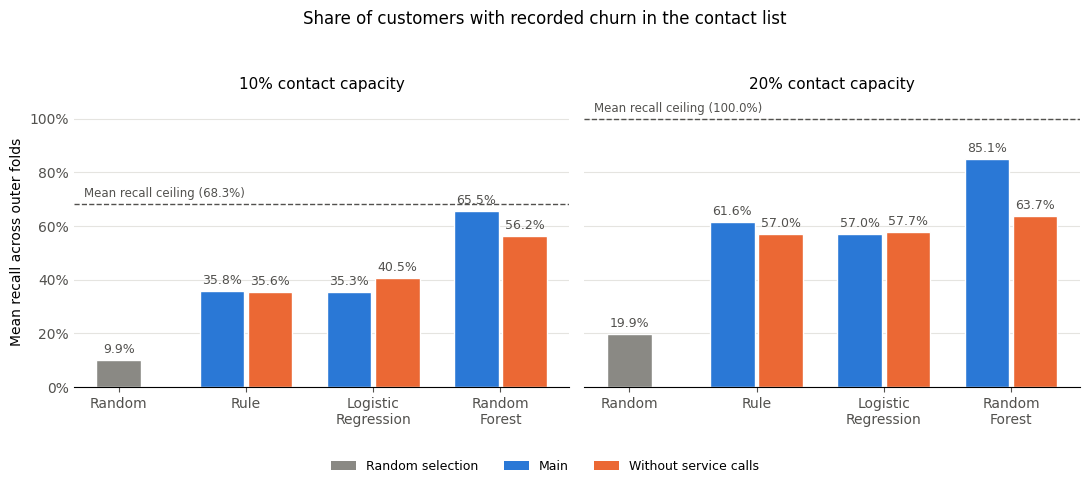

Saved reports/figures/modelling_01_recall_comparison.png


In [16]:
# === 7.3 Comparison chart ===
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter

VERSION_COLOURS = {
    "main": "#2a78d6",
    "without_service_calls": "#eb6834",
}
RANDOM_COLOUR = "#8a8984"
TEXT_COLOUR = "#52514e"

fig, axes = plt.subplots(
    1, len(CONTACT_CAPACITIES), figsize=(11, 4.8), sharey=True
)
bar_width = 0.38
positions = np.arange(len(METHOD_ORDER))
version_offsets = {
    "main": -bar_width / 2,
    "without_service_calls": bar_width / 2,
}

for ax, capacity in zip(np.atleast_1d(axes), CONTACT_CAPACITIES):
    subset = comparison_summary.loc[comparison_summary["capacity"].eq(capacity)]

    for version, offset in version_offsets.items():
        values = (
            subset.loc[subset["version"].eq(version)]
            .set_index("method")["recall_mean"]
            .reindex(METHOD_ORDER)
        )

        for position, (method, value) in zip(positions, values.items()):
            if method == "Random selection" and version != "main":
                continue

            x = position if method == "Random selection" else position + offset
            colour = (
                RANDOM_COLOUR if method == "Random selection"
                else VERSION_COLOURS[version]
            )

            ax.bar(
                x, value, width=bar_width - 0.03, color=colour,
                edgecolor="white", linewidth=1,
            )
            ax.annotate(
                f"{value:.1%}", (x, value),
                xytext=(0, 3), textcoords="offset points",
                ha="center", va="bottom", fontsize=9, color=TEXT_COLOUR,
            )

    ceiling = recall_ceiling[capacity]
    ax.axhline(ceiling, color=TEXT_COLOUR, linestyle="--", linewidth=1)
    ax.text(
        0.02, ceiling + 0.015, f"Mean recall ceiling ({ceiling:.1%})",
        transform=ax.get_yaxis_transform(), ha="left", va="bottom",
        fontsize=8.5, color=TEXT_COLOUR,
    )

    ax.set_title(f"{capacity:.0%} contact capacity", fontsize=11)
    ax.set_xticks(
        positions, ["Random", "Rule", "Logistic\nRegression", "Random\nForest"]
    )
    ax.set_ylim(0, 1.08)
    ax.set_yticks(np.linspace(0, 1, 6))
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
    ax.set_axisbelow(True)
    for spine in ("top", "right", "left"):
        ax.spines[spine].set_visible(False)
    ax.tick_params(axis="y", length=0, colors=TEXT_COLOUR)
    ax.tick_params(axis="x", colors=TEXT_COLOUR)

np.atleast_1d(axes)[0].set_ylabel("Mean recall across outer folds")

legend_handles = [Patch(facecolor=RANDOM_COLOUR, label="Random selection")]
legend_handles.extend(
    Patch(facecolor=colour, label=VERSION_LABELS[version])
    for version, colour in VERSION_COLOURS.items()
)
fig.legend(
    handles=legend_handles, loc="lower center", ncol=3,
    frameon=False, fontsize=9,
)
fig.suptitle(
    "Share of customers with recorded churn in the contact list",
    fontsize=12,
)
fig.tight_layout(rect=(0, 0.08, 1, 0.94))

comparison_figure = FIGURES / "modelling_01_recall_comparison.png"
fig.savefig(comparison_figure, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved {comparison_figure.relative_to(PROJECT)}")

### Comparison findings

**Main comparison.** Across the five outer validation folds, Random
Forest achieved the highest mean recall at both contact capacities.
At 10% capacity, mean recall was 65.5% for Random Forest, 35.8% for
the rule-based approach, 35.3% for Logistic Regression and 9.9% for
random selection. Random Forest was 2.8 percentage points below the
mean achievable recall ceiling of 68.3% across the five folds. Its
lowest fold-level recall at this capacity (62.8%) exceeded the highest
recall of the rule-based approach (40.3%) and Logistic Regression
(46.8%).

At 20% capacity, mean recall was 85.1% for Random Forest, 61.6% for
the rule-based approach, 57.0% for Logistic Regression and 19.9%
for random selection. Random Forest also achieved the highest mean
lift at both capacities, with 6.6 at 10% and 4.3 at 20%.

**Sensitivity to `Customer service calls`.** The main Random Forest
had higher recall than the version without this feature in all five
matched folds at both capacities. After removing the feature and
retuning, mean recall fell by 9.3 percentage points at 10% capacity
and 21.4 points at 20% capacity. For the rule-based approach, mean
recall fell by 0.3 and 4.6 points, respectively, with differences
varying across folds. For Logistic Regression, mean recall increased
by 5.1 points at 10% capacity. In the comparison without service calls,
Random Forest still achieved the highest mean recall at both capacities,
with 56.2% at 10% and 63.7% at 20%.

**Interpretation.** Random Forest's ability to model threshold-like
patterns in service calls is one possible explanation for its advantage.
The sensitivity analysis measures how performance changes after removing
the feature and retuning. Whether the call counts would have been
available at the time of prediction remains uncertain because their
timing relative to churn is undocumented.

These results come from cross-validation on the development data.
The reserved test set will be evaluated in `04_final_evaluation.ipynb`
after the model and rule settings have been fixed.

## 8. Final settings for the test evaluation

Nested cross-validation estimated the performance of each tuning
procedure on the development data. Since the selected settings could
vary across outer folds, this section selects one final configuration
for each tuned method and version before test evaluation.

The rule-based approach, Logistic Regression and Random Forest are
tuned using the same candidate grids and the five fold assignments
from Section 3. In each validation fold, candidates are scored using
the equally weighted mean of `Recall@10%` and `Recall@20%`. The
candidate with the highest average score across the five folds is
selected. Ties are resolved using the same candidate order as before.
Tuning is performed separately for the main version and the version
without `Customer service calls`. Random selection requires no tuning.

For the rule-based approach, each candidate percentile is converted
to a `Total day minutes` threshold using only the training partition
of that fold. After selection, the winning percentile is recalculated
on the full development set to obtain the final threshold.

The selected settings are saved to
`data/processed/modelling_decisions.json`. In `04_final_evaluation.ipynb`,
each selected model pipeline is fitted on the full development set.
The fitted models, fixed rules and random selection baseline are then
evaluated on the reserved test split at 10% and 20% contact capacity.

In [17]:
# === 8.1 Select final settings on the full development data ===
def select_final_candidate(candidates, build_pipeline, drop_service_calls=False):
    """Select one candidate by mean tuning score across the five CV folds."""
    best_score = -np.inf
    best_candidate = None

    for candidate in candidates:
        fold_scores = []

        for train_positions, valid_positions in outer_splits:
            pipeline = build_pipeline(candidate, drop_service_calls)
            pipeline.fit(X.iloc[train_positions], y.iloc[train_positions])
            scores = pipeline.predict_proba(X.iloc[valid_positions])[:, 1]
            ranking = rank_positions([scores])
            fold_scores.append(tuning_score(y.iloc[valid_positions], ranking))

        mean_score = float(np.mean(fold_scores))

        # Keep the first candidate when scores tie within numerical tolerance.
        if mean_score > best_score + 1e-12:
            best_score = mean_score
            best_candidate = candidate

    return dict(best_candidate), best_score


final_settings = {}

# Rule-based approach: the outer folds now act as the CV folds.
for version, service_thresholds in (
    ("main", SERVICE_CALL_THRESHOLDS),
    ("without_service_calls", (None,)),
):
    service_threshold, percentile, cv_score = select_rule_thresholds(
        X, y, outer_splits, service_thresholds
    )
    final_settings[("rule", version)] = {
        "service_calls_threshold": (
            None if service_threshold is None else int(service_threshold)
        ),
        "day_minutes_percentile": float(percentile),
        "day_minutes_threshold": float(
            np.percentile(X["Total day minutes"], percentile)
        ),
        "cv_tuning_score": cv_score,
    }

# Logistic Regression and Random Forest.
model_grids = {
    "logistic_regression": (lr_candidates, build_lr_candidate_pipeline),
    "random_forest": (rf_candidates, build_rf_candidate_pipeline),
}
for model_name, (candidates, build_pipeline) in model_grids.items():
    for version, drop_service_calls in (
        ("main", False),
        ("without_service_calls", True),
    ):
        candidate, cv_score = select_final_candidate(
            candidates, build_pipeline, drop_service_calls
        )
        final_settings[(model_name, version)] = {**candidate, "cv_tuning_score": cv_score}

final_settings_table = pd.DataFrame.from_dict(final_settings, orient="index")
final_settings_table.index.names = ["method", "version"]
display(final_settings_table.round(3))

service_calls_threshold  \
method              version                                          
rule                main                                       5.0   
                    without_service_calls                      NaN   
logistic_regression main                                       NaN   
                    without_service_calls                      NaN   
random_forest       main                                       NaN   
                    without_service_calls                      NaN   

                                           day_minutes_percentile  \
method              version                                         
rule                main                                     95.0   
                    without_service_calls                    95.0   
logistic_regression main                                      NaN   
                    without_service_calls                     NaN   
random_forest       main                                      NaN   
                    without_service_calls                     NaN   

                                           day_minutes_threshold  \
method              version                                        
rule                main                                 269.775   
                    without_service_calls                269.775   
logistic_regression main                                     NaN   
                    without_service_calls                    NaN   
random_forest       main                                     NaN   
                    without_service_calls                    NaN   

                                           cv_tuning_score  \
method              version                                  
rule                main                             0.503   
                    without_service_calls            0.463   
logistic_regression main                             0.473   
                    without_service_calls            0.502   
random_forest       main                             0.758   
                    without_service_calls            0.608   

                                                state_handling  \
method              version                                      
rule                main                                   NaN   
                    without_service_calls                  NaN   
logistic_regression main                   one_hot_regularised   
                    without_service_calls              exclude   
random_forest       main                               exclude   
                    without_service_calls              exclude   

                                          voicemail_features    C  \
method              version                                         
rule                main                                 NaN  NaN   
                    without_service_calls                NaN  NaN   
logistic_regression main                                both  0.1   
                    without_service_calls      messages_only  0.1   
random_forest       main                                both  NaN   
                    without_service_calls               both  NaN   

                                           min_samples_leaf  
method              version                                  
rule                main                                NaN  
                    without_service_calls               NaN  
logistic_regression main                                NaN  
                    without_service_calls               NaN  
random_forest       main                                1.0  
                    without_service_calls               5.0

In [18]:
# === 8.2 Save the modelling decisions ===
import json


def to_builtin(value):
    """Convert a NumPy scalar to a plain Python value for JSON."""
    return value.item() if isinstance(value, np.generic) else value


# Read the fixed settings from the builders used in Section 8.1.
rf_params = build_rf_candidate_pipeline(
    rf_candidates[0], False
).named_steps["model"].get_params(deep=False)

lr_params = build_lr_candidate_pipeline(
    lr_candidates[0], False
).named_steps["model"].get_params(deep=False)

modelling_decisions = {
    "source_notebook": "03_modelling.ipynb",
    "random_seed": int(RANDOM_SEED),
    "contact_capacities": [float(c) for c in CONTACT_CAPACITIES],
    "capacity_rounding": "floor",
    "tuning_criterion": "equally weighted mean of Recall@10% and Recall@20%",
    "final_selection": (
        f"{len(outer_splits)}-fold stratified CV on the full development data, "
        "using the outer folds from Section 3"
    ),
    "random_selection": {"n_orderings": int(N_RANDOM_ORDERINGS)},
    "random_forest_fixed_settings": {
        key: to_builtin(rf_params[key])
        for key in ("n_estimators", "max_features", "class_weight", "random_state")
    },
    "logistic_regression_fixed_settings": {
        key: to_builtin(lr_params[key])
        for key in ("solver", "class_weight", "max_iter")
    },
    "rule_ranking": "rule score, then Total day minutes, then seeded random order",
    "test_policy": audit_decisions["test_policy"],
    "selected_settings": {},
}

for (method, version), settings in final_settings.items():
    modelling_decisions["selected_settings"].setdefault(method, {})[version] = {
        key: to_builtin(value) for key, value in settings.items()
    }

decisions_path = PROJECT / "data" / "processed" / "modelling_decisions.json"
decisions_text = json.dumps(modelling_decisions, indent=2, allow_nan=False)
decisions_path.write_text(decisions_text + "\n", encoding="utf-8")

print(f"Saved {decisions_path.relative_to(PROJECT)}")
print(f"Random Forest trees recorded: {rf_params['n_estimators']}")
print(json.dumps(modelling_decisions["selected_settings"], indent=2))

Saved data/processed/modelling_decisions.json
Random Forest trees recorded: 100
{
  "rule": {
    "main": {
      "service_calls_threshold": 5,
      "day_minutes_percentile": 95.0,
      "day_minutes_threshold": 269.775,
      "cv_tuning_score": 0.5026806526806527
    },
    "without_service_calls": {
      "service_calls_threshold": null,
      "day_minutes_percentile": 95.0,
      "day_minutes_threshold": 269.775,
      "cv_tuning_score": 0.46267066267066265
    }
  },
  "logistic_regression": {
    "main": {
      "state_handling": "one_hot_regularised",
      "voicemail_features": "both",
      "C": 0.1,
      "cv_tuning_score": 0.47309357309357314
    },
    "without_service_calls": {
      "state_handling": "exclude",
      "voicemail_features": "messages_only",
      "C": 0.1,
      "cv_tuning_score": 0.5024975024975026
    }
  },
  "random_forest": {
    "main": {
      "state_handling": "exclude",
      "voicemail_features": "both",
      "min_samples_leaf": 1,
      "cv_tuni

### Final configurations selected

Five-fold cross-validation on the development set selected the following
configurations for evaluation on the reserved test split.

| Method | Main version | Without `Customer service calls` |
|---|---|---|
| Rule-based approach | Service-call threshold of 5 and daytime usage threshold of 269.775 minutes | Daytime usage threshold of 269.775 minutes |
| Logistic Regression | `C=0.1`, one-hot encoded `State`, and both voicemail features | `C=0.1`, `State` excluded, and `Number vmail messages` only |
| Random Forest | `State` excluded, both voicemail features, and `min_samples_leaf=1` | `State` excluded, both voicemail features, and `min_samples_leaf=5` |

Both rule variants selected the 95th percentile of `Total day minutes`.
The corresponding threshold of 269.775 minutes was calculated on the
full development set. Both Random Forest variants were configured
with 100 trees.

The configurations were saved in `data/processed/modelling_decisions.json`.
The `cv_tuning_score` values are the mean cross-validation scores of the
selected candidates. Because these scores were used to select the
candidates, they may be optimistic as estimates of performance on new
data. Section 7 reports performance on the outer validation folds of
nested cross-validation. Test-set recall and lift will be reported in
`04_final_evaluation.ipynb`.

## 9. Summary and outputs

This notebook compared random selection, a rule-based approach,
Logistic Regression and Random Forest at 10% and 20% contact capacity
on the same five outer validation folds of the development set. Model
settings and rule thresholds were selected within the inner folds.

Random Forest achieved the highest mean recall at both capacities,
with and without `Customer service calls`. In the main comparison,
the rule-based approach and Logistic Regression achieved similar
mean recall at 10% capacity. At 20% capacity, the rule-based approach
achieved higher mean recall than Logistic Regression (61.6% versus
57.0%). Both approaches outperformed random selection at both capacities.

Final settings for the rule-based approach and both models were
selected using five-fold cross-validation on the full development
set and saved for the reserved test evaluation.

### Saved outputs

**Decisions and fold assignments** (`data/processed/`)

- `outer_folds.csv` — outer validation fold assignment for each development record
- `modelling_decisions.json` — final settings for the reserved test evaluation

**Tables** (`reports/tables/`)

- `modelling_fold_summary.csv`
- `modelling_random_baseline_by_fold.csv`
- `modelling_rule_baseline_by_fold.csv`
- `modelling_lr_by_fold.csv`
- `modelling_rf_by_fold.csv`
- `modelling_comparison_summary.csv`
- `modelling_comparison_by_fold.csv`
- `modelling_sensitivity_differences.csv`

**Figure** (`reports/figures/`)

- `modelling_01_recall_comparison.png`

### Next step

`04_final_evaluation.ipynb` will read the saved settings and fit
Logistic Regression and Random Forest on the full development set.
The fitted models, fixed rules and random selection baseline will be
evaluated on the reserved test split at both contact capacities.
The notebook will also interpret model predictions using SHAP and
permutation feature importance.